# Report 1 — Denoising of low-cost sensors

## 1.2 Visualize your data

**Goal.** Understand the O$_3$ dataset before denoising:
1. Plot the temporal behaviour of the reference station (RefSt) and the two in-situ calibrated low-cost sensor (LCS) signals (MLR and SVR).
2. Quantify calibration quality with RMSE and $R^2$ against RefSt.
3. Organise the data into complete days (24 hourly samples), report how many days survive, and plot several days.

Figures are saved to `figures/` as PDF so they can be dropped straight into the report.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from sklearn.metrics import mean_squared_error, r2_score

FIG = Path("figures"); FIG.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.grid": True, "grid.alpha": 0.3})
COL = {"RefSt": "#2a7f62", "Sensor_MLR_O3": "#d1495b", "Sensor_SVR_O3": "#3d5a98"}
LBL = {"RefSt": "RefSt", "Sensor_MLR_O3": "LCS – MLR", "Sensor_SVR_O3": "LCS – SVR"}
SENSORS = ["Sensor_MLR_O3", "Sensor_SVR_O3"]

### Load the data

Timestamps are `dd/mm/yyyy HH:MM` (UTC). Parsing with an explicit format avoids pandas silently swapping day and month.

In [2]:
df = pd.read_csv("Report-1-Denoising.csv")
df["date"] = pd.to_datetime(df["date"], format="%d/%m/%Y %H:%M")
df = df.set_index("date").sort_index()

print(f"Samples: {len(df)}   from {df.index.min()}  to {df.index.max()}")
print(f"Missing values per column:\n{df.isna().sum()}")
print(f"Duplicated timestamps: {df.index.duplicated().sum()}")
df.describe().round(2)

Samples: 2907   from 2017-05-10 00:00:00  to 2017-10-05 08:00:00
Missing values per column:
RefSt            0
Sensor_MLR_O3    0
Sensor_SVR_O3    0
dtype: int64
Duplicated timestamps: 0


,RefSt,Sensor_MLR_O3,Sensor_SVR_O3
count,2907.00,2907.00,2907.00
mean,74.69,76.53,75.94
std,38.76,34.01,37.54
min,2.00,6.26,11.08
25%,46.00,48.92,45.78
50%,69.00,69.64,69.77
75%,100.00,103.92,103.07
max,224.00,164.77,227.64


### Gaps in the hourly series

The file has no NaNs, but missing hours are simply absent rows. Reindexing on a full hourly grid makes them explicit (and lets the plots show the gaps instead of drawing lines across them).

In [3]:
grid = pd.date_range(df.index.min().normalize(), df.index.max().normalize() + pd.Timedelta("23h"), freq="h")
dfg = df.reindex(grid)
print(f"Hours in the period: {len(grid)}   present: {len(df)}   missing: {dfg['RefSt'].isna().sum()} "
      f"({dfg['RefSt'].isna().mean():.1%})")

Hours in the period: 3576   present: 2907   missing: 669 (18.7%)


### Temporal behaviour — full period

Top: all three signals over the whole campaign. Bottom: a two-week zoom where the daily cycle of O$_3$ (photochemical peak in the afternoon, minimum at night) is clearly visible.

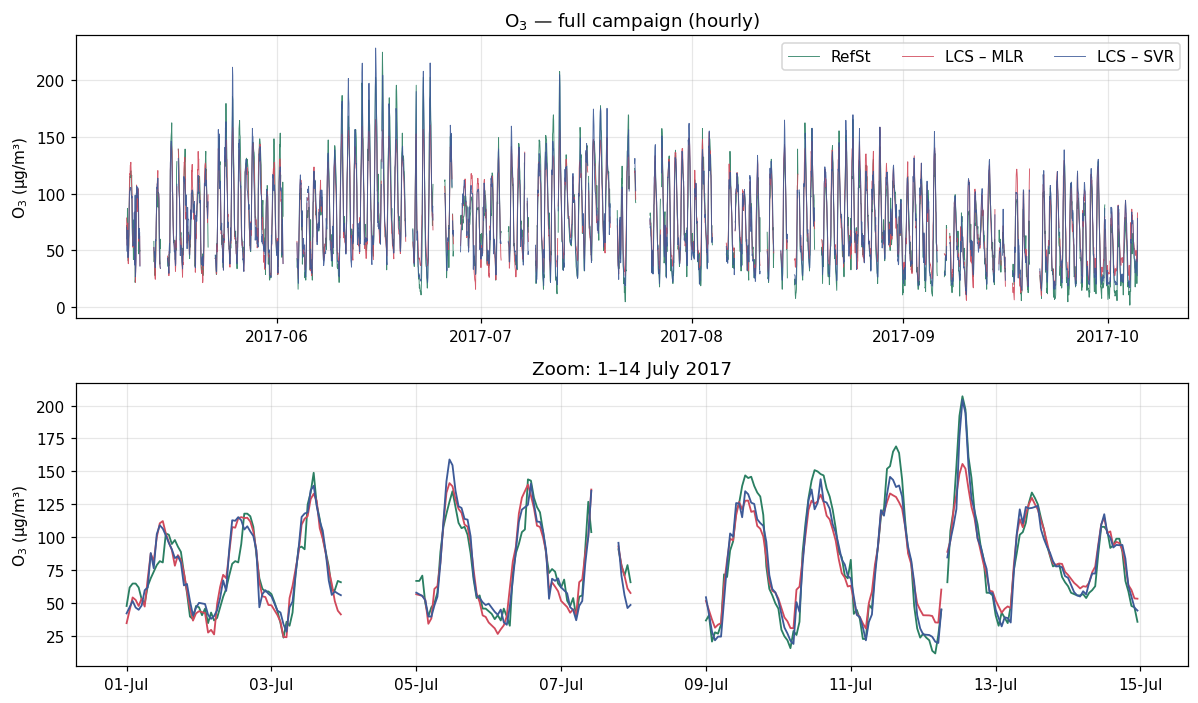

In [4]:
fig, axes = plt.subplots(2, 1, figsize=(11, 6.5))
for c in ["RefSt"] + SENSORS:
    axes[0].plot(dfg.index, dfg[c], lw=0.6, color=COL[c], label=LBL[c], alpha=0.9)
axes[0].set_title("O$_3$ — full campaign (hourly)")
axes[0].set_ylabel("O$_3$ (µg/m³)")
axes[0].legend(ncol=3, loc="upper right")

zoom = dfg.loc["2017-07-01":"2017-07-14"]
for c in ["RefSt"] + SENSORS:
    axes[1].plot(zoom.index, zoom[c], lw=1.2, color=COL[c], label=LBL[c])
axes[1].set_title("Zoom: 1–14 July 2017")
axes[1].set_ylabel("O$_3$ (µg/m³)")
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%d-%b"))
fig.tight_layout()
fig.savefig(FIG / "1_2_timeseries.pdf", bbox_inches="tight")
plt.show()

### Calibration quality: RMSE and $R^2$

$$\mathrm{RMSE}=\sqrt{\tfrac1N\sum_t (y_t-\hat y_t)^2},\qquad R^2 = 1-\frac{\sum_t (y_t-\hat y_t)^2}{\sum_t (y_t-\bar y)^2}$$

computed against RefSt over all available hourly samples. Mean bias ($\overline{\hat y - y}$) is added because it tells us whether a sensor systematically over/under-estimates.

In [5]:
def metrics(y, yhat):
    return {"RMSE": np.sqrt(mean_squared_error(y, yhat)),
            "R2": r2_score(y, yhat),
            "MAE": np.mean(np.abs(yhat - y)),
            "Bias": np.mean(yhat - y)}

calib = pd.DataFrame({LBL[s]: metrics(df["RefSt"], df[s]) for s in SENSORS}).T
calib.round(3)

,RMSE,R2,MAE,Bias
LCS – MLR,13.982,0.870,10.836,1.841
LCS – SVR,12.690,0.893,9.641,1.251


### Scatter plots and residuals

Scatter vs RefSt (the 1:1 line is the ideal calibration) and the residual distribution. MLR's limited dynamic range (max ≈165 vs RefSt max 224) should appear as a flattening at high concentrations.

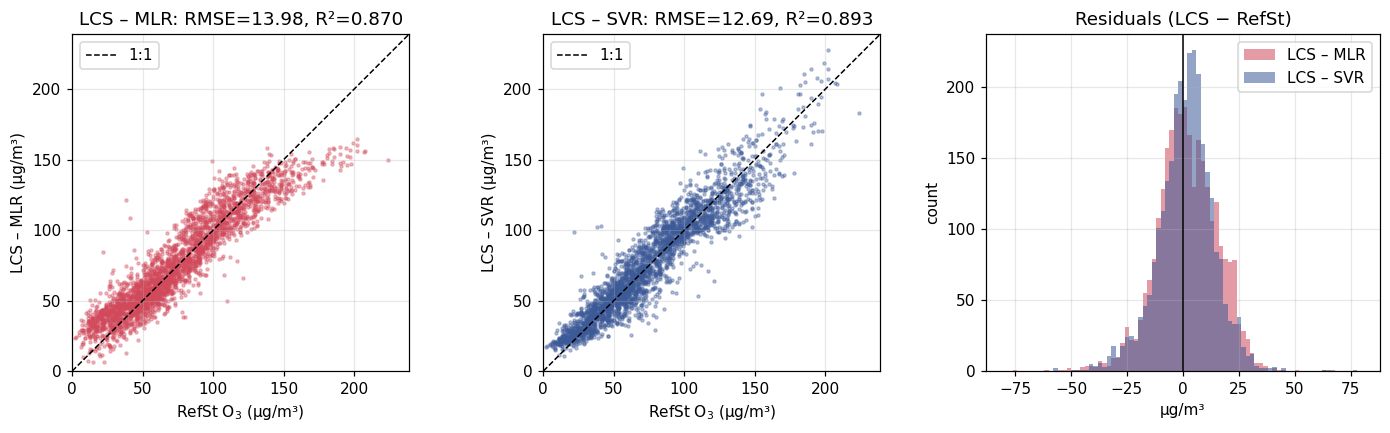

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
lim = [0, df[["RefSt"] + SENSORS].max().max() * 1.05]
for ax, s in zip(axes[:2], SENSORS):
    ax.scatter(df["RefSt"], df[s], s=4, alpha=0.35, color=COL[s])
    ax.plot(lim, lim, "k--", lw=1, label="1:1")
    ax.set(xlim=lim, ylim=lim, xlabel="RefSt O$_3$ (µg/m³)", ylabel=f"{LBL[s]} (µg/m³)",
           title=f"{LBL[s]}: RMSE={calib.loc[LBL[s],'RMSE']:.2f}, R²={calib.loc[LBL[s],'R2']:.3f}")
    ax.set_aspect("equal"); ax.legend(loc="upper left")

bins = np.linspace(-80, 80, 81)
for s in SENSORS:
    axes[2].hist(df[s] - df["RefSt"], bins=bins, alpha=0.55, color=COL[s], label=LBL[s])
axes[2].axvline(0, color="k", lw=1)
axes[2].set(title="Residuals (LCS − RefSt)", xlabel="µg/m³", ylabel="count")
axes[2].legend()
fig.tight_layout()
fig.savefig(FIG / "1_2_scatter_residuals.pdf", bbox_inches="tight")
plt.show()

### Organise the data into days

Each day becomes a vector $\mathbf x_i\in\mathbb R^{24}$ (hours 00–23). Days with any missing hour are discarded, since the eigenfaces approach needs all daily vectors to live in the same 24-dimensional space.

In [7]:
dfg["day"] = dfg.index.normalize()
dfg["hour"] = dfg.index.hour
n_hours = dfg.groupby("day")["RefSt"].count()

complete_days = n_hours[n_hours == 24].index
print(f"Calendar days in the period : {len(n_hours)}")
print(f"Days with at least one sample: {(n_hours > 0).sum()}")
print(f"Days with no data at all     : {(n_hours == 0).sum()}")
print(f"Incomplete days (1–23 h)     : {((n_hours > 0) & (n_hours < 24)).sum()}")
print(f"COMPLETE days (24 h)         : {len(complete_days)}")

def to_daily(col):
    m = dfg.pivot_table(index="day", columns="hour", values=col)
    return m.loc[complete_days]          # shape (days, 24)

Y_ref = to_daily("RefSt")
X_mlr = to_daily("Sensor_MLR_O3")
X_svr = to_daily("Sensor_SVR_O3")
print("Daily matrices:", Y_ref.shape, X_mlr.shape, X_svr.shape)

Calendar days in the period : 149
Days with at least one sample: 127
Days with no data at all     : 22
Incomplete days (1–23 h)     : 23
COMPLETE days (24 h)         : 104
Daily matrices: (104, 24) (104, 24) (104, 24)


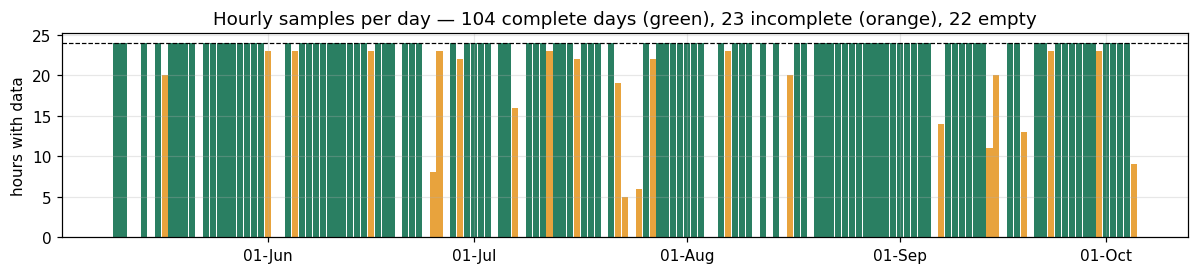

In [8]:
fig, ax = plt.subplots(figsize=(11, 2.6))
colors = np.where(n_hours.values == 24, "#2a7f62", np.where(n_hours.values == 0, "#bbbbbb", "#e8a33d"))
ax.bar(n_hours.index, n_hours.values, width=0.9, color=colors)
ax.axhline(24, color="k", lw=0.8, ls="--")
ax.set(ylabel="hours with data", title=f"Hourly samples per day — {len(complete_days)} complete days (green), "
       f"{((n_hours>0)&(n_hours<24)).sum()} incomplete (orange), {(n_hours==0).sum()} empty")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d-%b"))
fig.tight_layout()
fig.savefig(FIG / "1_2_day_completeness.pdf", bbox_inches="tight")
plt.show()

Calibration metrics restricted to the complete days — this is the baseline the denoising step (1.3) has to beat, so it must be computed on exactly the same samples.

In [9]:
calib_days = pd.DataFrame({
    "LCS – MLR": metrics(Y_ref.values.ravel(), X_mlr.values.ravel()),
    "LCS – SVR": metrics(Y_ref.values.ravel(), X_svr.values.ravel()),
}).T
calib_days.round(3)

,RMSE,R2,MAE,Bias
LCS – MLR,13.424,0.876,10.523,1.801
LCS – SVR,12.455,0.894,9.525,1.447


### Daily profiles

Several individual days comparing RefSt with both calibrated sensors, chosen to cover low, medium and high O$_3$ days (by daily mean of RefSt).

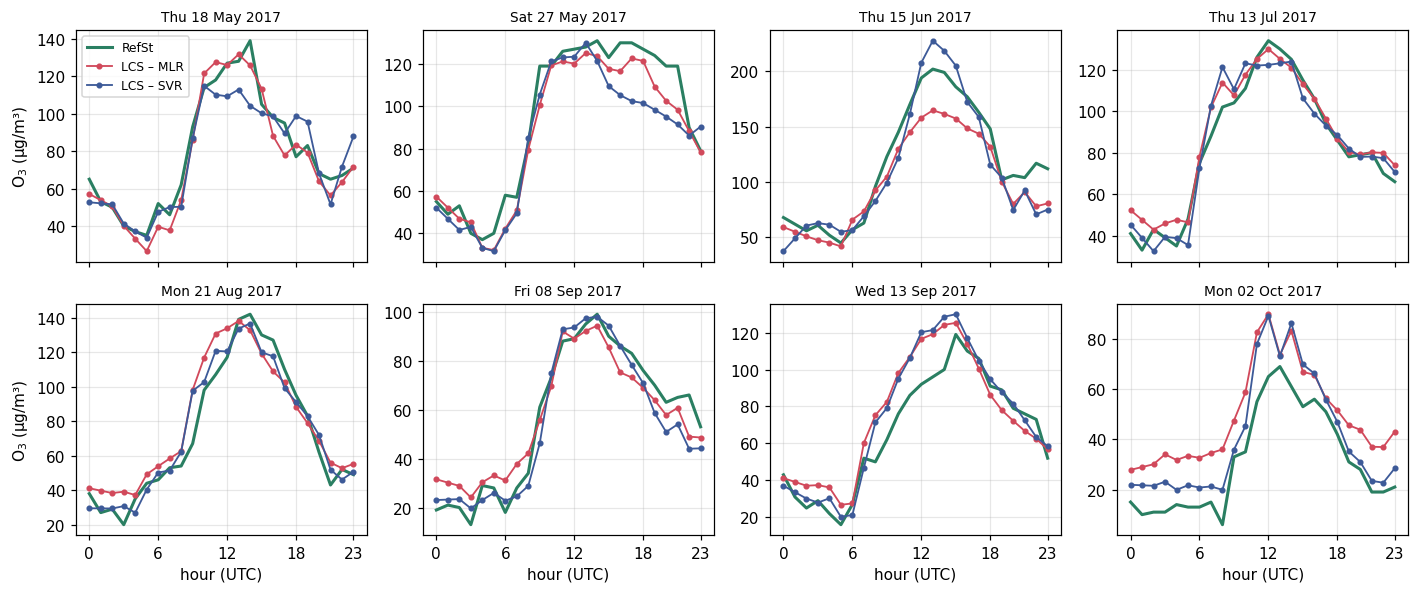

In [10]:
order = Y_ref.mean(axis=1).sort_values().index
pick = order[np.linspace(0, len(order) - 1, 8).round().astype(int)]
hours = np.arange(24)

fig, axes = plt.subplots(2, 4, figsize=(13, 5.5), sharex=True)
for ax, d in zip(axes.ravel(), sorted(pick)):
    ax.plot(hours, Y_ref.loc[d], color=COL["RefSt"], lw=2, label="RefSt")
    ax.plot(hours, X_mlr.loc[d], color=COL["Sensor_MLR_O3"], lw=1.2, marker=".", label="LCS – MLR")
    ax.plot(hours, X_svr.loc[d], color=COL["Sensor_SVR_O3"], lw=1.2, marker=".", label="LCS – SVR")
    ax.set_title(d.strftime("%a %d %b %Y"), fontsize=9)
    ax.set_xticks([0, 6, 12, 18, 23])
for ax in axes[:, 0]: ax.set_ylabel("O$_3$ (µg/m³)")
for ax in axes[1]: ax.set_xlabel("hour (UTC)")
axes[0, 0].legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIG / "1_2_daily_examples.pdf", bbox_inches="tight")
plt.show()

### All complete days at once

Every complete day overlaid (thin lines) with the mean daily profile $\boldsymbol\Psi$ (bold) and ±1 std band. The strong, shared diurnal shape is the reason a low-dimensional subspace of reference days should describe new days well — the core assumption of the eigenfaces denoising in 1.3.

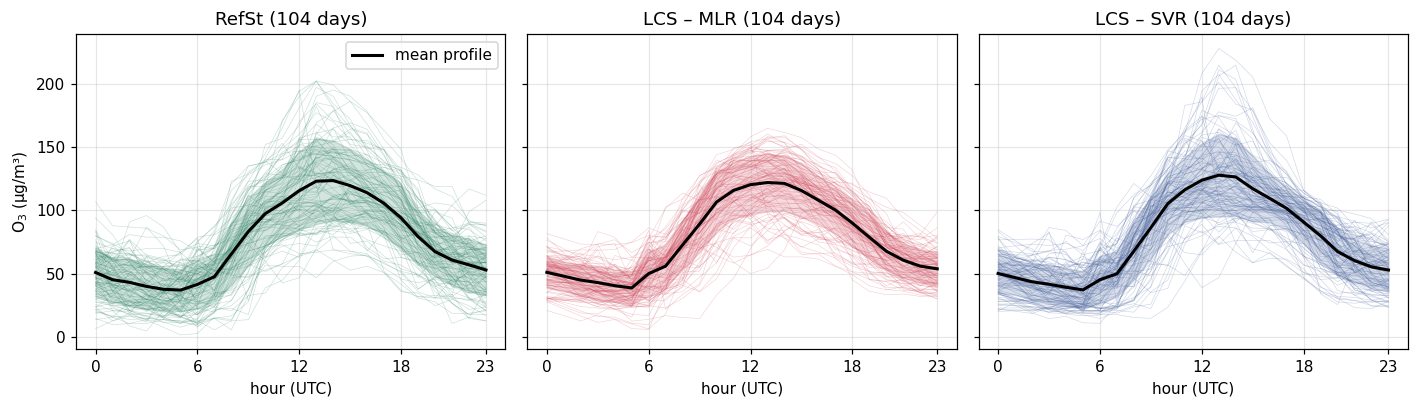

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
for ax, (name, M, c) in zip(axes, [("RefSt", Y_ref, "RefSt"), ("LCS – MLR", X_mlr, "Sensor_MLR_O3"),
                                    ("LCS – SVR", X_svr, "Sensor_SVR_O3")]):
    ax.plot(hours, M.T.values, color=COL[c], lw=0.4, alpha=0.25)
    mu, sd = M.mean(), M.std()
    ax.fill_between(hours, mu - sd, mu + sd, color=COL[c], alpha=0.2)
    ax.plot(hours, mu, color="k", lw=2, label="mean profile")
    ax.set(title=f"{name} ({len(M)} days)", xlabel="hour (UTC)", xticks=[0, 6, 12, 18, 23])
axes[0].set_ylabel("O$_3$ (µg/m³)"); axes[0].legend()
fig.tight_layout()
fig.savefig(FIG / "1_2_daily_overlay.pdf", bbox_inches="tight")
plt.show()

### Error by hour of day

RMSE of each sensor computed separately for every hour across the complete days. This shows *when* the calibration struggles (e.g. at the afternoon peak), which is exactly the kind of structured error that projecting onto the reference subspace can correct.

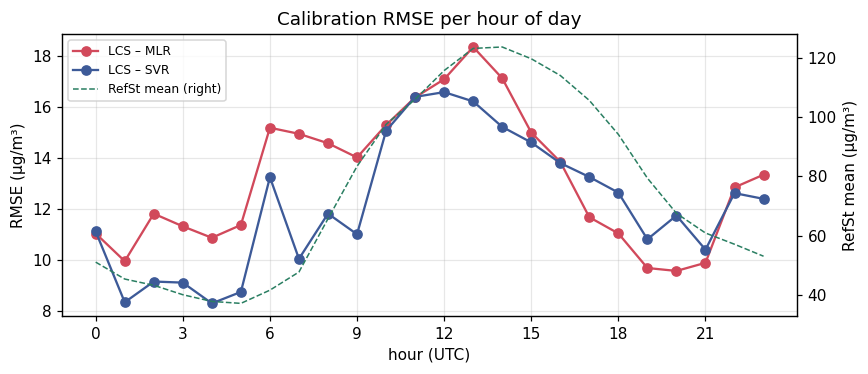

In [12]:
rmse_h = pd.DataFrame({
    "LCS – MLR": np.sqrt(((X_mlr - Y_ref) ** 2).mean()),
    "LCS – SVR": np.sqrt(((X_svr - Y_ref) ** 2).mean()),
})
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(hours, rmse_h["LCS – MLR"], marker="o", color=COL["Sensor_MLR_O3"], label="LCS – MLR")
ax.plot(hours, rmse_h["LCS – SVR"], marker="o", color=COL["Sensor_SVR_O3"], label="LCS – SVR")
ax2 = ax.twinx(); ax2.grid(False)
ax2.plot(hours, Y_ref.mean(), color=COL["RefSt"], ls="--", lw=1, label="RefSt mean (right)")
ax2.set_ylabel("RefSt mean (µg/m³)")
ax.set(xlabel="hour (UTC)", ylabel="RMSE (µg/m³)", title="Calibration RMSE per hour of day", xticks=range(0, 24, 3))
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, fontsize=8, loc="upper left")
fig.tight_layout()
fig.savefig(FIG / "1_2_rmse_by_hour.pdf", bbox_inches="tight")
plt.show()

### Save the daily matrices for 1.3

In [13]:
daily = pd.concat({"RefSt": Y_ref, "MLR": X_mlr, "SVR": X_svr}, axis=1)
daily.to_csv("daily_complete_days.csv")
print(daily.shape)

(104, 72)


### Observations

- **Data coverage.** 2907 hourly samples from 10 May to 5 Oct 2017. 669 hours (18.7%) are missing. Of the 149 calendar days, 22 have no data and 23 are incomplete, so **104 complete days** are left. The daily matrices are $104\times 24$.
- **Calibration quality (all samples).** SVR is better than MLR: RMSE 12.69 vs 13.98 µg/m³, $R^2$ 0.893 vs 0.870. Both have a small positive bias (+1.3 and +1.8 µg/m³). On the 104 complete days, which is the baseline for 1.3, the figures are MLR RMSE 13.42 / $R^2$ 0.876 and SVR RMSE 12.46 / $R^2$ 0.894.
- **Dynamic range.** MLR compresses the extremes. It overestimates low values and saturates near ~165 µg/m³ while RefSt reaches 224 µg/m³, so the scatter flattens at the top. SVR follows the 1:1 line over the whole range but scatters more on individual points.
- **When the errors happen.** RMSE is highest around the afternoon photochemical peak (12–15 UTC, about 16–18 µg/m³) and lowest at night. MLR also has a jump in error at 6–9 UTC, during the morning ramp-up. On low-O$_3$ days (e.g. 2 Oct) both sensors sit well above RefSt all day.
- **Motivation for 1.3.** Every complete day has the same diurnal shape: low at night, a rise after sunrise and a peak at 12–15 UTC. The daily vectors should therefore lie close to a low-dimensional subspace of reference days. Projecting the LCS daily vectors onto that subspace should remove some of the calibration noise.
